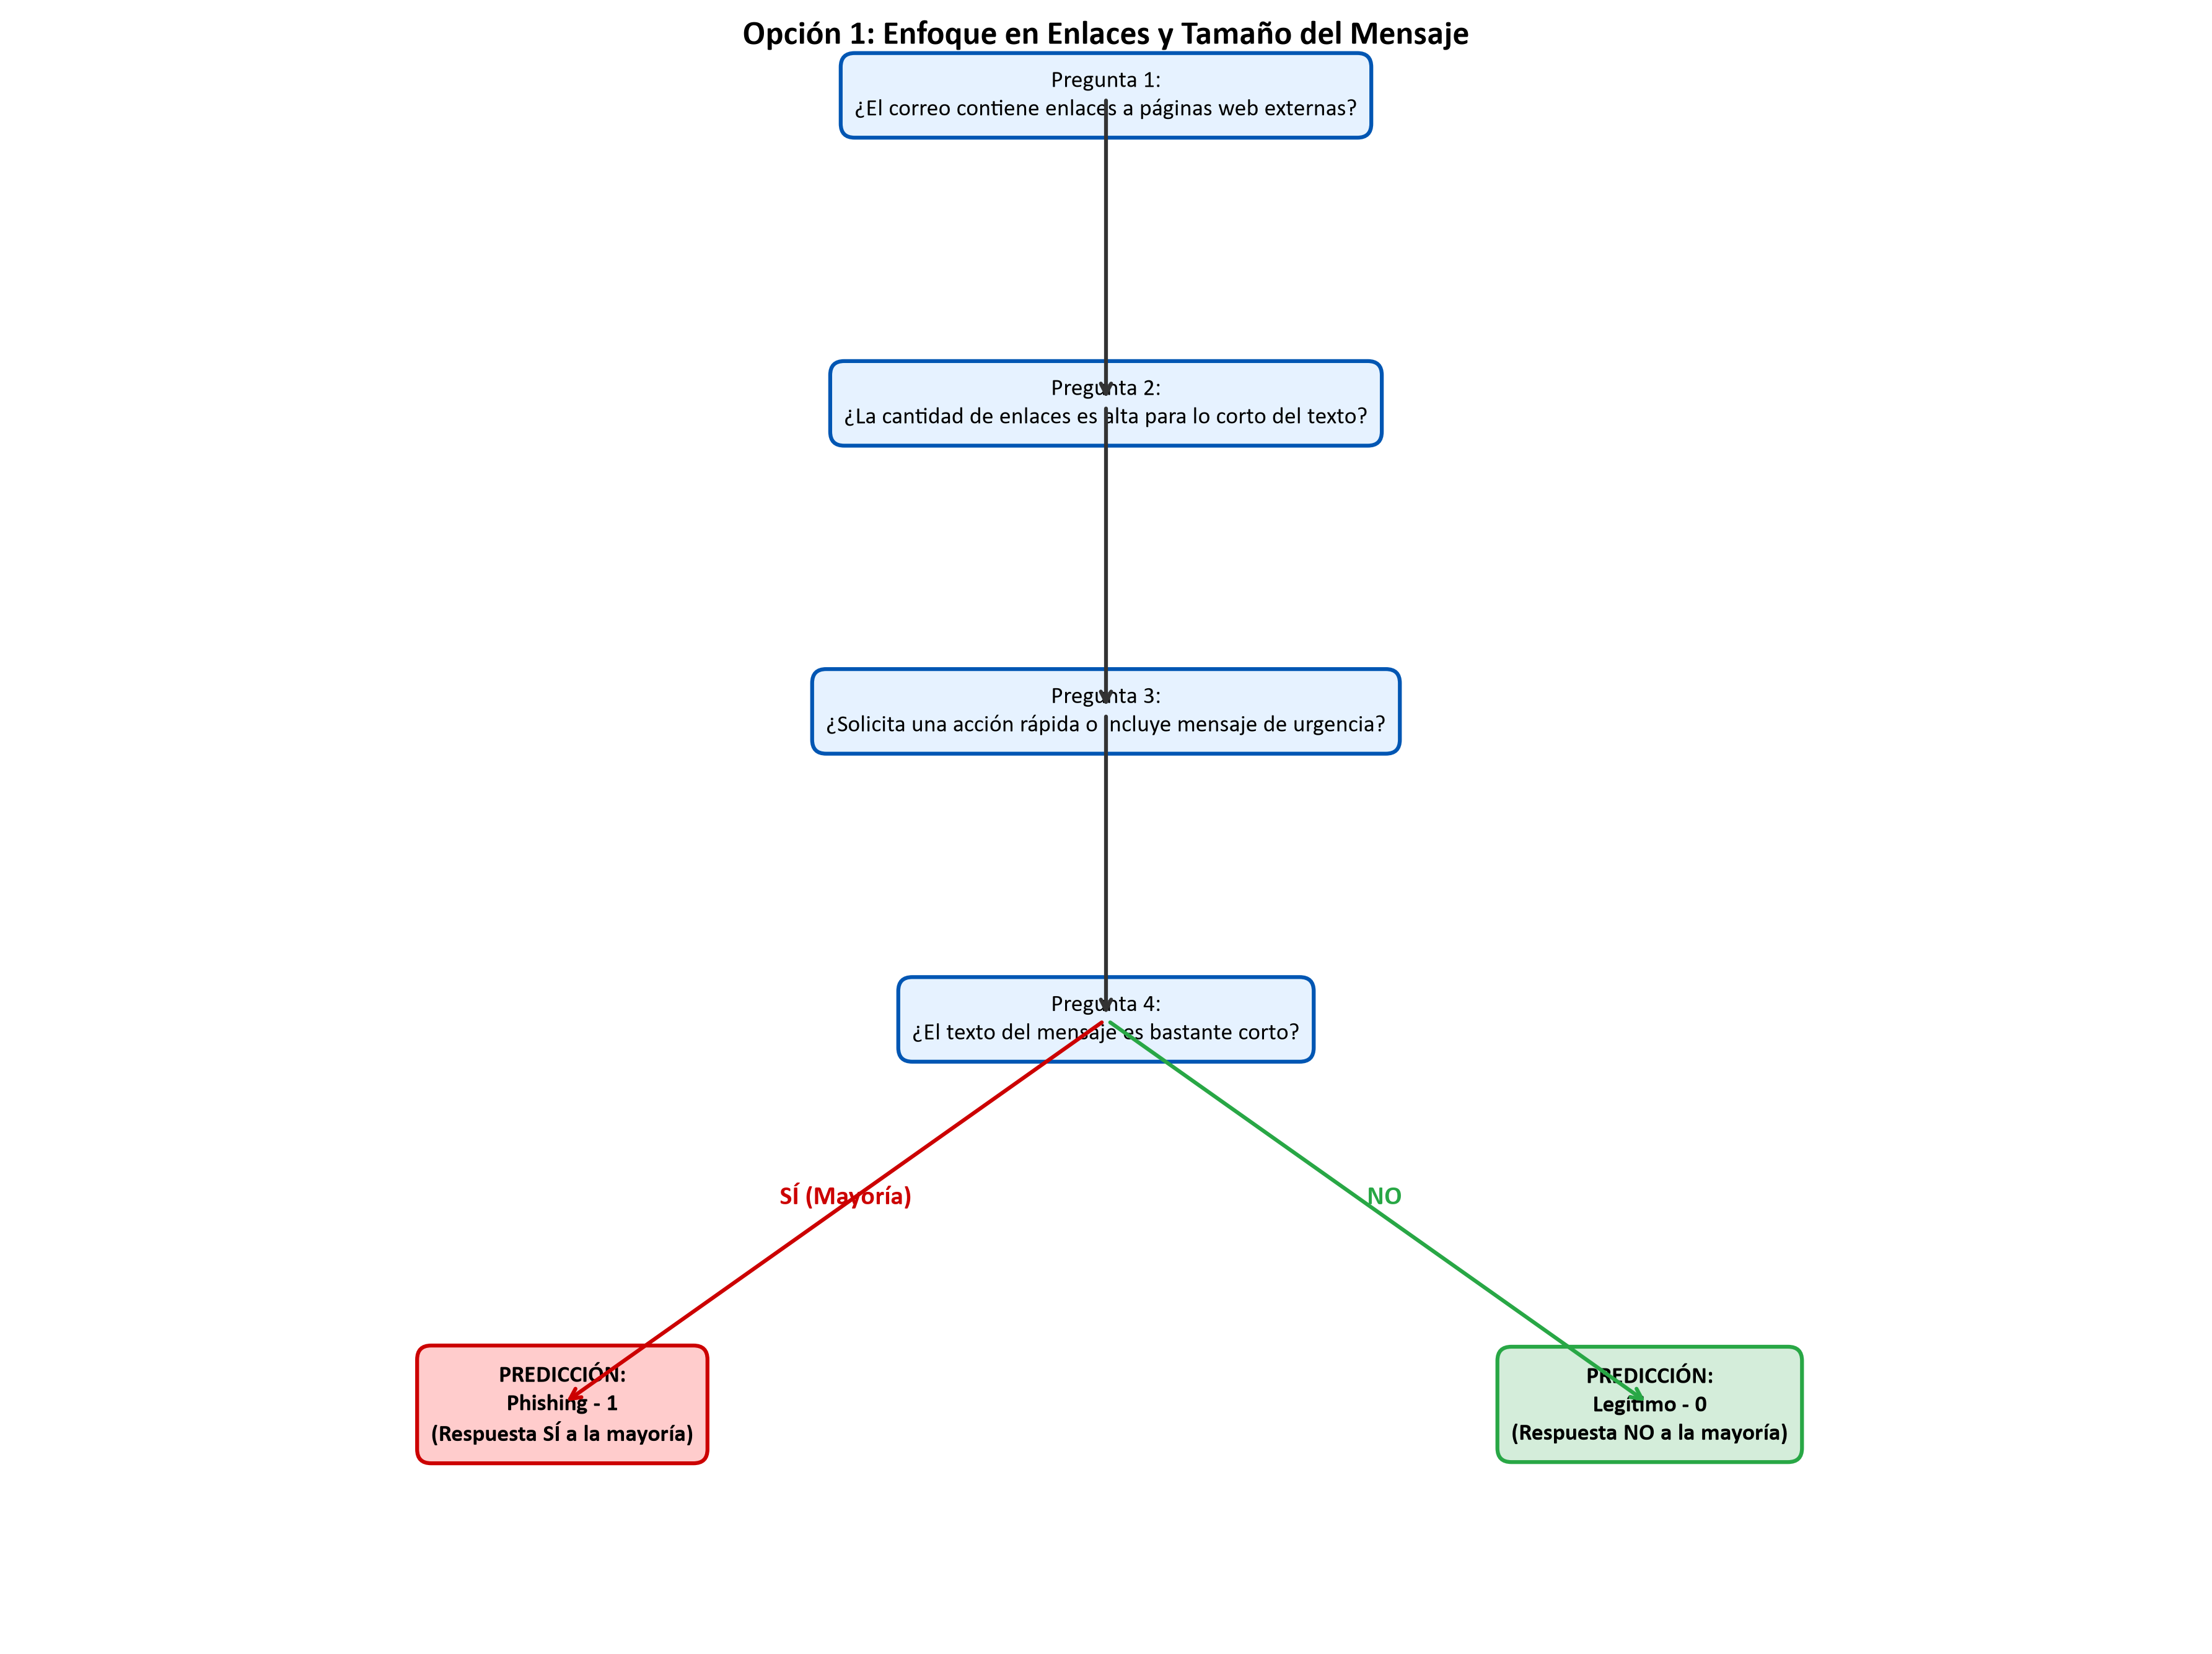

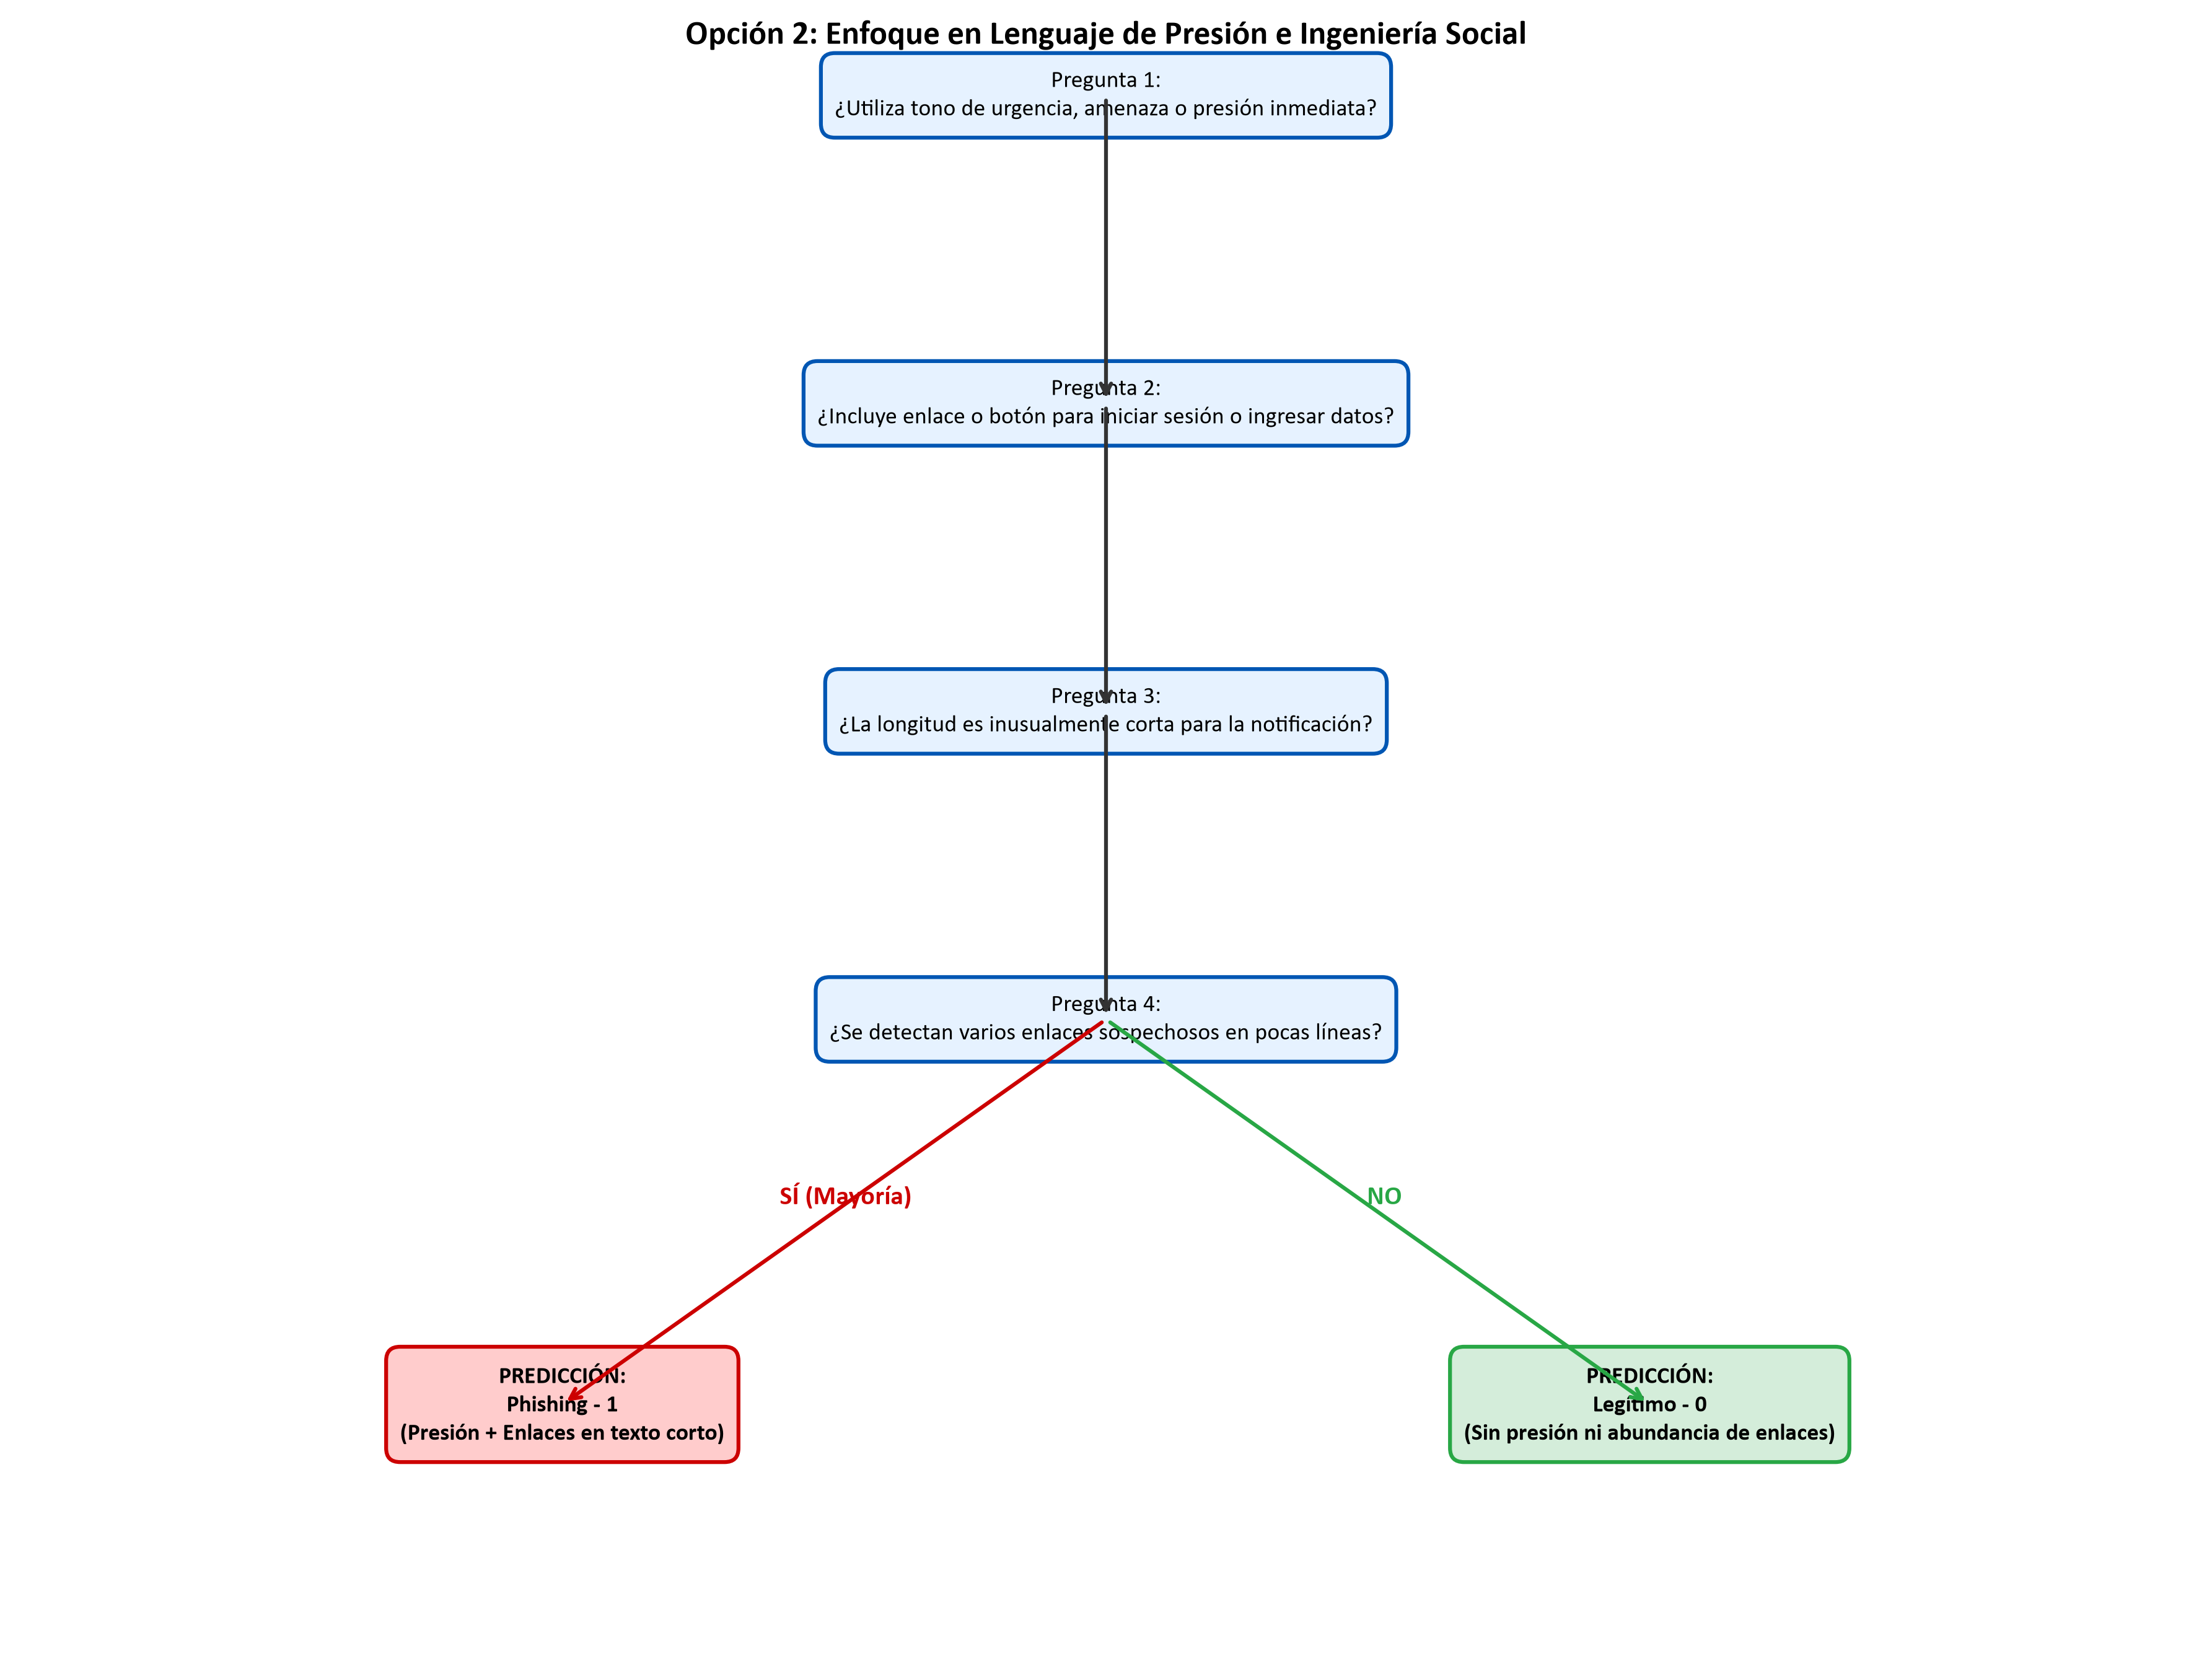

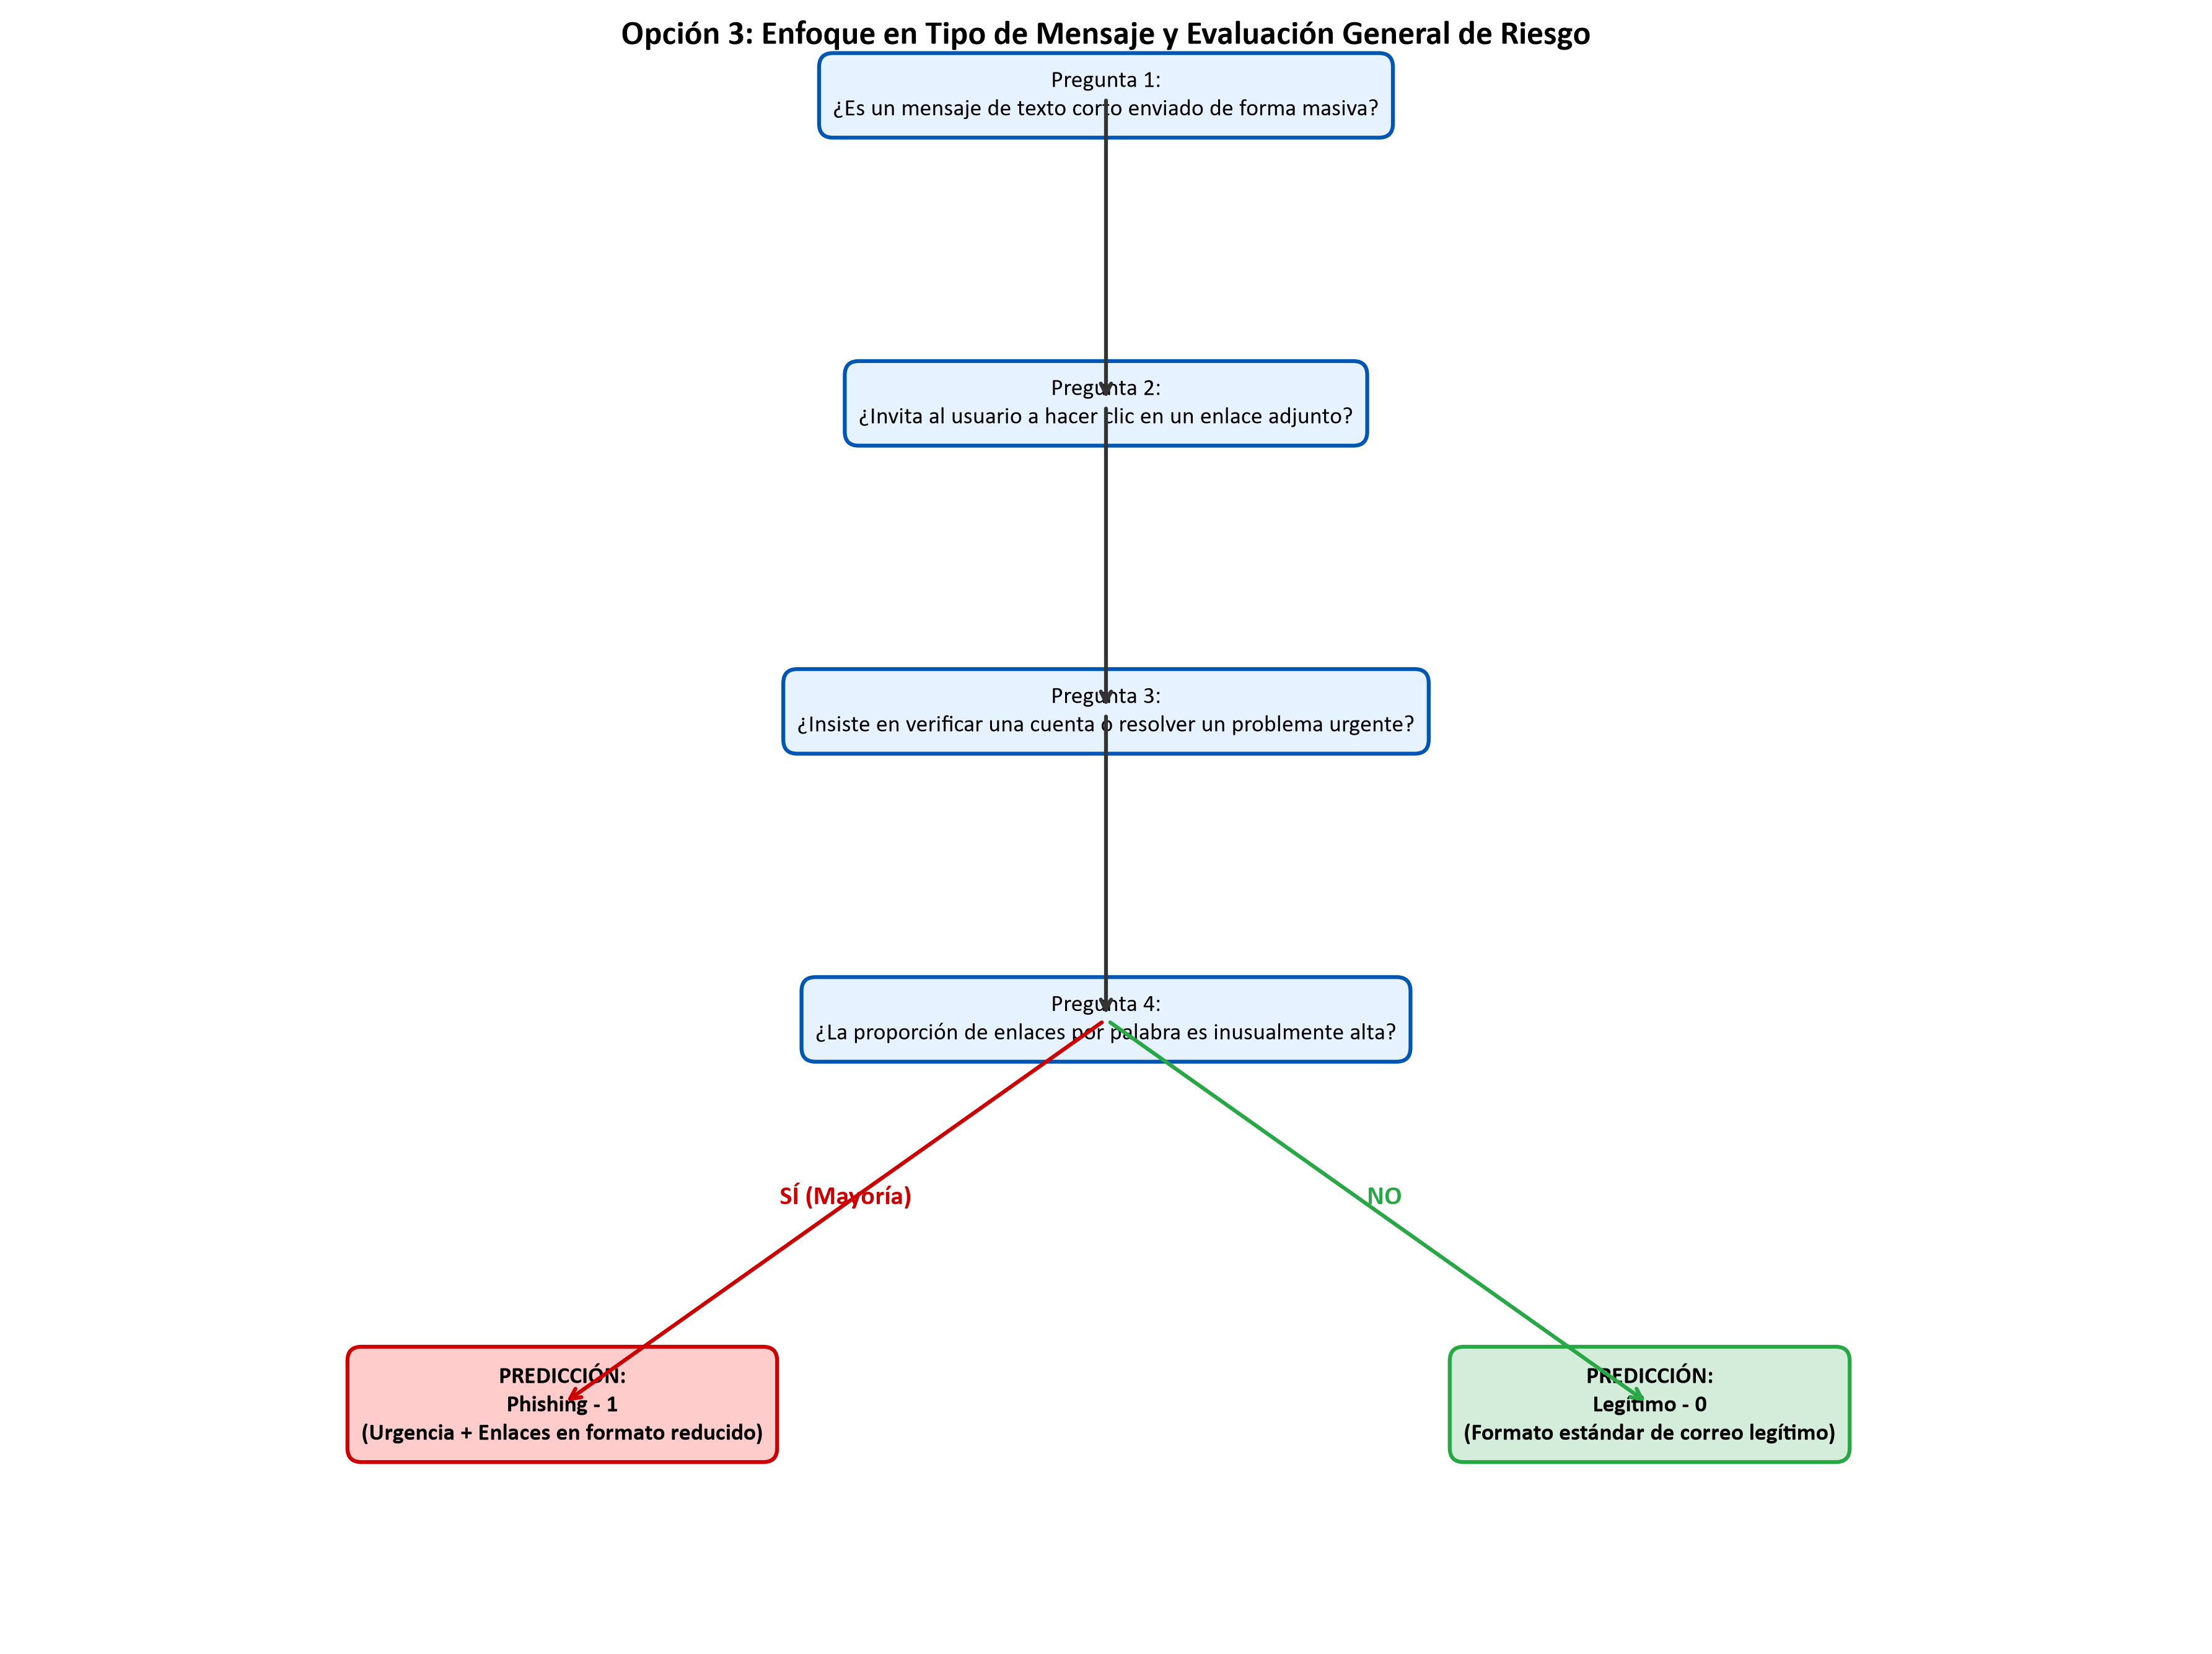

In [1]:
# ==========================================
# VISUALIZACIÓN CONCEPTUAL DE 3 ÁRBOLES DE DECISIÓN (4 PREGUNTAS)
# PROYECTO CYCLOPS SENTINEL
# ==========================================

import matplotlib.pyplot as plt
import networkx as nx

# Ajuste global de tipografía
plt.rcParams['font.sans-serif'] = 'Calibri'

def dibujar_arbol_conceptual(titulo, preguntas, regla_si, regla_no):
    """
    Función para graficar la secuencia de 4 preguntas de un árbol de decisión conceptual.
    """
    G = nx.DiGraph()
    
    # Nodos del árbol
    nodes = {
        'P1': f"Pregunta 1:\n{preguntas[0]}",
        'P2': f"Pregunta 2:\n{preguntas[1]}",
        'P3': f"Pregunta 3:\n{preguntas[2]}",
        'P4': f"Pregunta 4:\n{preguntas[3]}",
        'PRED_SI': f"PREDICCIÓN:\nPhishing - 1\n({regla_si})",
        'PRED_NO': f"PREDICCIÓN:\nLegítimo - 0\n({regla_no})"
    }
    
    # Posiciones verticales para simular los 4 niveles
    pos = {
        'P1': (0.5, 1.0),
        'P2': (0.5, 0.8),
        'P3': (0.5, 0.6),
        'P4': (0.5, 0.4),
        'PRED_SI': (0.25, 0.15),
        'PRED_NO': (0.75, 0.15)
    }
    
    fig, ax = plt.subplots(figsize=(12, 9), dpi=300)
    ax.set_title(titulo, fontsize=13, fontweight='bold', pad=20)
    
    # Dibujar Nodos de Preguntas (Niveles 0 a 3)
    for node_id in ['P1', 'P2', 'P3', 'P4']:
        ax.text(
            pos[node_id][0], pos[node_id][1], nodes[node_id],
            ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#e6f2ff', edgecolor='#0056b3', lw=1.5)
        )
    
    # Dibujar Nodos de Predicción Final
    ax.text(
        pos['PRED_SI'][0], pos['PRED_SI'][1], nodes['PRED_SI'],
        ha='center', va='center', fontsize=9, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffcccc', edgecolor='#cc0000', lw=1.5)
    )
    ax.text(
        pos['PRED_NO'][0], pos['PRED_NO'][1], nodes['PRED_NO'],
        ha='center', va='center', fontsize=9, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#d4edda', edgecolor='#28a745', lw=1.5)
    )
    
    # Flechas entre preguntas
    ax.annotate('', xy=pos['P2'], xytext=pos['P1'], arrowprops=dict(arrowstyle='->', lw=1.5, color='#333333'))
    ax.annotate('', xy=pos['P3'], xytext=pos['P2'], arrowprops=dict(arrowstyle='->', lw=1.5, color='#333333'))
    ax.annotate('', xy=pos['P4'], xytext=pos['P3'], arrowprops=dict(arrowstyle='->', lw=1.5, color='#333333'))
    
    # Flechas finales hacia las predicciones
    ax.annotate('', xy=pos['PRED_SI'], xytext=pos['P4'], arrowprops=dict(arrowstyle='->', lw=1.5, color='#cc0000'))
    ax.annotate('', xy=pos['PRED_NO'], xytext=pos['P4'], arrowprops=dict(arrowstyle='->', lw=1.5, color='#28a745'))
    
    # Etiquetas de decisión final
    ax.text(0.35, 0.28, 'SÍ (Mayoría)', color='#cc0000', fontweight='bold', fontsize=10)
    ax.text(0.62, 0.28, 'NO', color='#28a745', fontweight='bold', fontsize=10)
    
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# ==========================================
# OPCIÓN 1: ENFOQUE EN ENLACES Y TAMAÑO
# ==========================================
preguntas_opt1 = [
    "¿El correo contiene enlaces a páginas web externas?",
    "¿La cantidad de enlaces es alta para lo corto del texto?",
    "¿Solicita una acción rápida o incluye mensaje de urgencia?",
    "¿El texto del mensaje es bastante corto?"
]
dibujar_arbol_conceptual(
    "Opción 1: Enfoque en Enlaces y Tamaño del Mensaje",
    preguntas_opt1,
    "Respuesta SÍ a la mayoría",
    "Respuesta NO a la mayoría"
)

# ==========================================
# OPCIÓN 2: LENGUAJE DE PRESIÓN E INGENIERÍA SOCIAL
# ==========================================
preguntas_opt2 = [
    "¿Utiliza tono de urgencia, amenaza o presión inmediata?",
    "¿Incluye enlace o botón para iniciar sesión o ingresar datos?",
    "¿La longitud es inusualmente corta para la notificación?",
    "¿Se detectan varios enlaces sospechosos en pocas líneas?"
]
dibujar_arbol_conceptual(
    "Opción 2: Enfoque en Lenguaje de Presión e Ingeniería Social",
    preguntas_opt2,
    "Presión + Enlaces en texto corto",
    "Sin presión ni abundancia de enlaces"
)

# ==========================================
# OPCIÓN 3: TIPO DE MENSAJE Y EVALUACIÓN DE RIESGO
# ==========================================
preguntas_opt3 = [
    "¿Es un mensaje de texto corto enviado de forma masiva?",
    "¿Invita al usuario a hacer clic en un enlace adjunto?",
    "¿Insiste en verificar una cuenta o resolver un problema urgente?",
    "¿La proporción de enlaces por palabra es inusualmente alta?"
]
dibujar_arbol_conceptual(
    "Opción 3: Enfoque en Tipo de Mensaje y Evaluación General de Riesgo",
    preguntas_opt3,
    "Urgencia + Enlaces en formato reducido",
    "Formato estándar de correo legítimo"
)